# A15 crop suitability per LGA: our data against each crop's requirements

For 14 crops (the nine with a water balance, plus rice, ginger, yam, lablab and Stylosanthes), this notebook asks whether each LGA's own climate and soil suit the crop. Crop requirements come from the FAO ECOCROP database (absolute and optimal ranges for temperature, season rain, soil pH and texture). The LGA side is our data: POWER monthly temperature and CHIRPS monthly rain for every year from 1981 to 2025, and iSDA cropland pH, sand and clay.

Method: the EcoCrop model (Hijmans et al. 2001). Each requirement is scored 0 outside its absolute range, 1 inside its optimal range, linear between. A season scores the lower of temperature (worst month) and rain (season total). Every start month is tried; the best one per LGA is kept. Settings: `config/models.yaml` (`suitability`). Formulas: `model/suitability.py`.

This answers three open items from data: drought tolerance (rain against each crop's minimum), heat tolerance (hottest month against its optimum) and pH and texture fit. It also gives rice, ginger and yam a water assessment, from rain, where FAO-56 has no crop coefficients for the bucket.

## Imports

In [1]:
# Third-party libraries only. Project code is imported two cells down, after the path
# setup, so this cell runs in any fresh kernel.
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Path setup: makes the notebook work whether Jupyter starts in notebooks/ or the repo
# root, and lets `import model` find the project package.
# Run from notebooks/ or the repo root: config paths are relative to the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
# Project code: the tested functions in model/. The notebook calls them; it never
# redefines them, so its results match `python -m model.build` exactly.
from model import suitability as su
from model.io import write_csv
from model.settings import load_crop_config, load_model_config
from model.water_pipeline import canonical_lga

## 1. Crop requirements (ECOCROP) and LGA data

In [4]:
# Load ECOCROP requirements for the 14 crops, monthly temperature (mean of POWER Tmax and
# Tmin) and CHIRPS rain for 1981-2025, iSDA cropland soil, and each crop's season length.
# Scope: all 23 Kaduna LGAs.
cfg = load_model_config()
sc = cfg.suitability
lgas = sorted(cfg.lga_zone)
ecocrop = pd.read_csv(sc.ecocrop).set_index("crop")
monthly = pd.read_parquet(
    cfg.paths.monthly_features,
    columns=["lga", "year", "month", "power_tmax_mean_c", "power_tmin_mean_c", "rain_mm"],
)
monthly = monthly[monthly["year"].between(sc.years.start, sc.years.end)].assign(
    tmean_c=lambda d: (d["power_tmax_mean_c"] + d["power_tmin_mean_c"]) / 2
)
isda = pd.read_csv(cfg.paths.isda_stats)
isda = isda.assign(lga=canonical_lga(isda["lga"], lgas)).set_index("lga")
season_days = {k: c.stages_days.total for k, c in load_crop_config().crops.items()}
ecocrop[
    ["NAME", "TOPMN", "TOPMX", "TMAX", "RMIN", "ROPMN", "ROPMX", "PHMIN", "PHMAX", "TEXT", "TEXTR"]
]

,NAME,TOPMN,TOPMX,TMAX,RMIN,ROPMN,ROPMX,PHMIN,PHMAX,TEXT,TEXTR
crop,,,,,,,,,,,
maize,Maize,18,33,47,400,600,1200,4.5,8.5,M O,W
sorghum,Sorghum (med. altitude),24,35,40,300,500,1000,5.0,8.5,M H,W
millet,Pearl millet,25,35,40,200,400,900,4.5,8.3,L M,L M
soybean,Soyabean,20,33,38,450,600,1500,4.5,8.4,M O,W
cowpea,Cowpea,20,35,40,400,600,1500,4.3,8.8,M,W
groundnut,Groundnut,22,32,45,400,600,1500,4.5,8.5,M,W O
sesame,Sesame seed,20,30,40,300,500,1000,4.5,8.0,M,W
cassava,Cassava,20,29,35,500,1000,1500,4.0,9.0,L M,W O
tomato,Tomato,20,27,35,400,600,1300,5.0,7.5,M O,W


## 2. Score every crop in every LGA

In [5]:
# Score every crop in every LGA: every start month and year, then the best start month.
table = su.crop_suitability(monthly, isda, ecocrop, season_days, sc.suitable_score)
table.groupby("crop")[
    ["mean_score", "share_years_suitable", "rain_short_share", "heat_share", "ph_score"]
].median().round(2).sort_values("mean_score")

,mean_score,share_years_suitable,rain_short_share,heat_share,ph_score
crop,,,,,
rice,0.68,0.87,0.56,0.00,1.00
ginger,0.70,0.93,0.98,0.31,0.93
yam,0.82,1.00,0.04,0.00,0.13
millet,0.92,1.00,0.04,0.00,1.00
sorghum,0.97,1.00,0.00,0.00,0.88
stylosanthes,0.97,1.00,0.04,0.02,1.00
cassava,0.98,1.00,0.04,0.04,1.00
groundnut,1.00,1.00,0.00,0.00,1.00
lablab,1.00,1.00,0.00,0.00,1.00


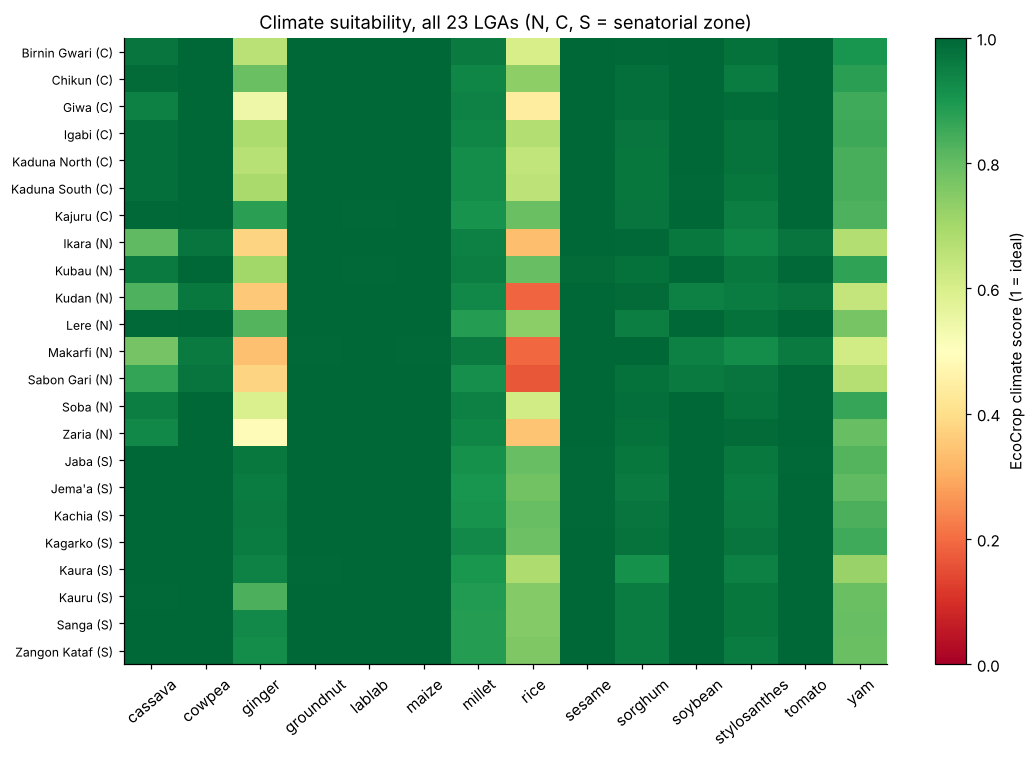

In [6]:
# Climate score for every LGA and crop, grouped by senatorial zone.
grid = table.pivot(index="lga", columns="crop", values="mean_score")
grid = grid.loc[sorted(grid.index, key=lambda name: (cfg.lga_zone[name], name))]
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(grid, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(grid.shape[1]), grid.columns, rotation=40)
ax.set_yticks(range(len(grid)), [f"{n} ({cfg.lga_zone[n][0]})" for n in grid.index], fontsize=8)
fig.colorbar(im, label="EcoCrop climate score (1 = ideal)")
ax.set_title("Climate suitability, all 23 LGAs (N, C, S = senatorial zone)")
plt.tight_layout()

## 3. Does the data put crops where Kaduna farmers grow them?

In [7]:
# The same score averaged by zone, for crops whose location in Kaduna is known.
by_zone = (
    table.assign(zone=table["lga"].map(cfg.lga_zone))
    .pivot_table(index="crop", columns="zone", values="mean_score")
    .round(2)
)
by_zone.loc[["ginger", "yam", "rice", "millet", "sorghum", "maize"]]

zone,Central,North,South
crop,,,
ginger,0.70,0.51,0.93
yam,0.86,0.74,0.80
rice,0.65,0.42,0.76
millet,0.93,0.93,0.90
sorghum,0.98,0.98,0.96
maize,1.00,1.00,1.00


**Reading.** Ginger scores highest in the south and lowest in the north, where its long season runs short of rain: that matches where Kaduna's ginger is grown (Kachia, Jaba, Kagarko). Millet and sorghum score well everywhere, and the cereals and legumes of the rotation templates fit every LGA. Upland rice is limited by rain in the north; Kaduna's rice is mostly grown in wet lowlands (fadama), which a rain-only score cannot see.

## 4. Soil: pH and texture

In [8]:
# pH score, LGAs ruled out on pH, and texture fit counts per crop.
soil = table.pivot_table(index="crop", values=["ph_score", "ph_outside"], aggfunc="mean").round(2)
soil.join(table.groupby("crop")["texture_fit"].value_counts().unstack(fill_value=0))

,ph_outside,ph_score,optimal,outside,tolerated
crop,,,,,
cassava,0.00,1.00,23,0,0
cowpea,0.00,1.00,11,0,12
ginger,0.00,0.92,11,0,12
groundnut,0.00,1.00,11,0,12
lablab,0.00,1.00,23,0,0
maize,0.00,1.00,11,0,12
millet,0.00,1.00,23,0,0
rice,0.00,1.00,0,12,11
sesame,0.00,1.00,11,0,12


iSDA cropland pH runs only 5.6 to 6.1 across Kaduna, inside most crops' optimum. The exception is yam: ECOCROP gives white yam a minimum pH of 5.8, stricter than the southern LGAs where yam is widely grown, so only an LGA where even the most alkaline tenth of cropland is below 5.8 is ruled out, and the rest get a risk line. Twelve LGAs have light (sandy) cropland, which ECOCROP marks as outside the range for yam and upland rice: a risk line, since LGA means hide heavier fields.

## 5. Save

In [9]:
# Save the table the rotation engine reads.
write_csv(table, cfg.paths.suitability)

PosixPath('data/processed/models/a15/a15_lga_crop_suitability.csv')